<img src="https://raw.githubusercontent.com/gustavomartinellidev/ai-governance-lab/main/assets/profile.png" width="120" align="left" style="border-radius:50%; margin:6px 24px 12px 0;" alt="Gustavo Martinelli">

# 🔎 Third-Party AI Risk Assessment with a Decision Model

### Screening vendor questionnaire answers with Jev (TypeSafe AI), from an AI governance perspective

**Gustavo Martinelli** · AI Engineer &amp; AI Governance Specialist · <a href="https://www.linkedin.com/in/gustavomartinelli/" target="_blank">🔗 Connect on LinkedIn</a>

<br clear="all">

👋 **Welcome!** In this notebook we take **30 answers** from three (fictional) AI vendors to a security and AI-governance questionnaire and ask a **decision model**, not a chatbot, to screen each one. The model returns **typed, calibrated judgments**; the policy that turns those judgments into **PASS / REVIEW / FAIL** lives in a few lines of Python that anyone can read and audit.

The goal is not to automate vendor assessment here, but to show what a **screening layer with human oversight by design** can look like. The same building blocks (typed decisions, a policy in code, a human review queue) are exactly what a production **AI automation for third-party AI risk assessment** would be made of: connect it to your questionnaire tool, run it on every submission, and route the output to your GRC platform.

The same approach also scales: it can be built into an AI automation that runs third-party AI risk assessments end to end.

A proof of concept (PoC) is the recommended first step, to find the best design for that automation. Keep in mind that the EU AI Act (Art. 14) and ISO/IEC 42001 (A.9.2–A.9.4) require human oversight, so the automation does not remove the human reviewer; it concentrates human attention on the vendors and answers that the screening flags. How far to take it depends on each company's needs and risk appetite.

📌 **Assumptions:** deploying this kind of solution presupposes that the organization already has the foundational policies in place: an information security policy, a privacy policy, a risk management policy, a supplier (third-party) risk management policy and an AI acceptable use policy. The screening layer enforces those policies; **it does not replace them**.

▶️ **How to use:** this notebook is published **with its outputs saved**, so you can read every result without running anything. To run it yourself you need a TypeSafe API key ([typesafe.ai](https://typesafe.ai)), stored in Colab **Secrets** (🔑 icon on the left) as `TYPESAFE_API_KEY`. Then `Runtime → Run all`. It makes 30 API calls, takes about a minute, needs no GPU, and the total cost is a fraction of a cent.

## 📣 About This Post

> *This notebook accompanies my LinkedIn post. Here is the full text:*

**🔎 I ran 30 vendor security answers through an AI model that cannot write a single sentence.**

Third-party risk assessment is one of the most repetitive jobs in AI governance. Read a vendor's answer to a questionnaire. Decide whether it addresses the control, whether there is evidence, whether something in it is a red flag. Repeat, for hundreds of answers.

In September, TypeSafe AI released **Jev**, a "System One" decision model. It does not generate text. You give it a piece of state and a set of typed questions, and it returns typed answers with probabilities: a yes/no with a probability, a choice among labels, a score on a rubric.

So I built a small experiment (Colab in the first comment):

- 3 fictional AI vendors, 10 controls each, mapped to ISO/IEC 27001, ISO/IEC 42001, NIST AI RMF and EU AI Act deployer duties. 30 synthetic answers.
- 4 typed questions per answer: does it address the control? What kind of evidence? How specific? Is there a red flag?
- The decision policy (PASS / REVIEW / FAIL) lives in about 15 lines of Python, not inside the model.

Results: **8 PASS, 5 REVIEW, 17 FAIL**. Median latency 88 ms per answer, total cost under one cent.

The vendor that answered every control with polished marketing language ("security is in our DNA") scored between 0.02 and 0.09 on "addresses the control", ten times out of ten. The model was not fooled by polish. The vendor that quietly admitted training shared models on customer data got a red-flag probability of 0.97. And two of the strongest answers still went to human review, because the model reported low confidence. The policy errs toward people.

Three governance lessons:

1️⃣ **Typed outputs are auditable outputs.** A probability of 0.97 can be logged, thresholded and contested. A paragraph of prose cannot.

2️⃣ **Keep the policy out of the model.** The model judges, the code decides, a human reviews the gray zone. That is human oversight by design, not by promise.

3️⃣ **The screening tool is itself a third party.** Pinned model version, synthetic data, no real vendor documents. Governance applies to the tools we use to govern.

This is a screening layer, not an assessment. It does not replace reading the SOC 2 report or the DPA. It tells you which of 300 answers to read first. Here, 5 of 30.

Where would you set the threshold for "this one needs a human"? 0.7? 0.9?

\#AIGovernance #ThirdPartyRisk #TPRM #ISO42001 #ISO27001 #ResponsibleAI #TypeSafeAI #Jev

## 🗺️ Roadmap

Each section answers a question an auditor, a CISO, a DPO or a procurement lead could ask about an AI-assisted vendor assessment.

| Section | What we do | Governance question |
|---|---|---|
| 1. Setup | Install the SDK, load the API key, pin the model version | *Can the result be reproduced? Is the key handled safely?* |
| 2. The Scenario | Define 10 controls and 30 synthetic vendor answers | *What exactly are we assessing, and against which standards?* |
| 3. The Decision Model | Explain Jev and define 4 typed questions | *What is the system, and what can it output?* |
| 4. Running the Screening | Send each answer to Jev and log every decision | *Is every judgment traceable to a model version and a timestamp?* |
| 5. The Decision Policy | Turn judgments into PASS / REVIEW / FAIL in code | *Who decides: the model, the code or a human?* |
| 6. Vendor Risk Tiers | Aggregate findings per vendor and visualize them | *Can we communicate the result clearly?* |
| 7. Assessment Report | Write a plain-language report (TXT and PDF) | *Can a non-technical reviewer understand and file it?* |

## 1. ⚙️ Setup

### 1.1 Libraries

We install one library, **`typesafe-sdk`**, the official Python client for Jev. Everything else (pandas, matplotlib) comes preinstalled in Google Colab. `fpdf2` is installed later, only for the PDF report.

We also fix a **random seed**. Jev itself is a remote model, so its answers are not under our control; the seed only guarantees that everything *we* do (sampling, ordering) is reproducible.

> 🏛️ **Governance note:** Reproducibility is a prerequisite for any audit. Part of it is under our control (code, data, thresholds) and part of it is not (a remote model that may be updated). Section 1.3 deals with the second part.

In [13]:
%pip install -q typesafe-sdk

import os
import json
import time
import random
import hashlib
import statistics
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

from typesafe_sdk import TypeSafeClient, Choice, Score, Noul
import typesafe_sdk

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

AUTHOR = "Gustavo Martinelli"

print(f"typesafe-sdk {typesafe_sdk.__version__} | pandas {pd.__version__} | seed = {SEED}")

typesafe-sdk 0.7.5 | pandas 2.2.3 | seed = 42


### 1.2 The API key

The key is read from **Colab Secrets** (`TYPESAFE_API_KEY`). If it is not there, the notebook asks for it with a hidden prompt. It is **never written in a cell**, never printed, and never saved with the notebook.

> 🏛️ **Governance note:** An API key is a credential. Treat it like a password: no hardcoding, no sharing in screenshots, rotate it if it leaks. This is ISO/IEC 27001 Annex A **5.17 (authentication information)** in its most practical form.

In [14]:
from getpass import getpass

try:
    from google.colab import userdata          # Colab Secrets (🔑 panel on the left)
    os.environ["TYPESAFE_API_KEY"] = userdata.get("TYPESAFE_API_KEY")
except Exception:
    if not os.environ.get("TYPESAFE_API_KEY"):
        os.environ["TYPESAFE_API_KEY"] = getpass("Paste your TypeSafe API key (hidden, not saved): ")

print("API key loaded:", "yes" if os.environ.get("TYPESAFE_API_KEY") else "NO - the next cells will fail")

API key loaded: yes


### 1.3 Pinning the model version

The SDK defaults to `jev-latest`, which **moves** whenever TypeSafe ships an update. We pin an explicit version instead, so the same answer produces the same judgment next month.

This is the decision-model equivalent of the **model fingerprint** we computed in the previous notebook: every logged decision is tied to one specific model version.

> 🏛️ **Governance note:** ISO/IEC 42001 Annex A **6.2.6** (AI system operation and monitoring) and **A.8.2** (system documentation) both assume you know *which* model produced a result. "Latest" is not a version.

In [15]:
MODEL = "jev-1.13.0"     # pinned on purpose; see docs.typesafe.ai for the current list

client = TypeSafeClient(model=MODEL)   # reads TYPESAFE_API_KEY from the environment
print(f"Client ready | model pinned to {MODEL}")

Client ready | model pinned to jev-1.13.0


## 2. 🏢 The Scenario

### 2.1 Context

We are a company evaluating three vendors of an **AI customer-support assistant**. The assistant reads customer tickets (which contain personal data), drafts replies and can trigger refunds. Under the EU AI Act we would be the **deployer**; under the GDPR and Brazil's LGPD we are the **controller** and the vendor is a **processor**.

Before signing, we sent each vendor the same **10-control questionnaire**. Each control is mapped to the standards that motivate it:

| ID | Control | Why it matters here | Mapped to |
|---|---|---|---|
| C01 | **Use of customer data for training** | Our customers' tickets must not become someone else's training set without a legal basis | ISO/IEC 42001 A.7.2–A.7.4 · ISO/IEC 27701 · GDPR Art. 28 · LGPD Art. 39 |
| C02 | **Subprocessors and model providers** | The vendor's own AI supply chain is our fourth-party risk | ISO/IEC 27001 A.5.19–5.21 · ISO/IEC 42001 A.10.3 · NIST AI RMF GOVERN 6.1 |
| C03 | **Encryption in transit and at rest** | Baseline confidentiality of ticket data | ISO/IEC 27001 A.8.24 |
| C04 | **Access control and logging** | Who at the vendor can read our data, and is it recorded | ISO/IEC 27001 A.5.15, A.8.15 · ISO/IEC 42001 A.6.2.8 |
| C05 | **Security incident notification** | We have our own 72-hour clock (GDPR Art. 33, LGPD Art. 48) | ISO/IEC 27001 A.5.24–5.26 |
| C06 | **AI incident and malfunction reporting** | Wrong refunds and harmful replies are AI incidents, not just bugs | ISO/IEC 42001 A.8.4 · EU AI Act Art. 73 (for high-risk systems) |
| C07 | **Human oversight and escalation** | Someone must be able to stop, override and review the assistant | ISO/IEC 42001 A.9.2–A.9.4 · EU AI Act Art. 14, Art. 26 |
| C08 | **Model documentation and change notification** | We cannot govern a model that changes silently | ISO/IEC 42001 A.8.2, A.6.2.7 · EU AI Act Art. 13 |
| C09 | **Data retention and deletion** | Tickets must not live forever in the vendor's logs | ISO/IEC 27701 · GDPR Art. 5(1)(e) · LGPD Art. 15–16 |
| C10 | **Independent assurance** | Claims are cheap; third-party audits are not | ISO/IEC 27001 A.5.22 · NIST AI RMF GOVERN 6.1 |

> 🏛️ **Governance note:** A questionnaire is only as good as its mapping. Each control above answers "*which obligation would we breach if the vendor fails this?*". Controls that cannot answer that question are usually noise.

In [16]:
CONTROLS = [
    ("C01", "Use of customer data for training",
     "The vendor must not use the customer's data (tickets, attachments, metadata) to train, fine-tune or evaluate "
     "models for other customers without an explicit, documented legal basis and the customer's written agreement."),
    ("C02", "Subprocessors and model providers",
     "The vendor must disclose all subprocessors, including third-party AI model providers and hosting regions, "
     "and notify the customer before adding or changing one."),
    ("C03", "Encryption in transit and at rest",
     "Customer data must be encrypted in transit (TLS 1.2 or higher) and at rest (AES-256 or equivalent), "
     "with documented key management."),
    ("C04", "Access control and logging",
     "Access to customer data by vendor staff must be role-based, limited to the minimum necessary, and logged, "
     "with logs available to the customer on request."),
    ("C05", "Security incident notification",
     "The vendor must notify the customer of a confirmed security incident affecting its data within a defined "
     "deadline (72 hours or less), including the facts needed for the customer's own regulatory notifications."),
    ("C06", "AI incident and malfunction reporting",
     "The vendor must report AI-specific incidents (harmful outputs, wrong automated actions, systematic errors, "
     "model failures) to the customer, with a defined process and timeline."),
    ("C07", "Human oversight and escalation",
     "The customer must be able to configure human review of the assistant's actions, override or stop it, "
     "and route sensitive cases to a human agent."),
    ("C08", "Model documentation and change notification",
     "The vendor must provide documentation of the model in use (provider, version, intended use, known "
     "limitations, evaluation results) and notify the customer before material model changes."),
    ("C09", "Data retention and deletion",
     "The vendor must define retention periods for customer data, including logs and prompts, and delete "
     "or return the data on request and at termination, with confirmation."),
    ("C10", "Independent assurance",
     "The vendor must provide current independent evidence of its controls (e.g. SOC 2 Type II report, "
     "ISO/IEC 27001 or ISO/IEC 42001 certificate, penetration test summary)."),
]
CONTROL_NAME = {cid: name for cid, name, _ in CONTROLS}
CONTROL_REQ = {cid: req for cid, _, req in CONTROLS}

# Controls whose failure is disqualifying on its own for this use case
CRITICAL_CONTROLS = {"C01", "C05", "C07"}

print(f"{len(CONTROLS)} controls defined | critical: {', '.join(sorted(CRITICAL_CONTROLS))}")

10 controls defined | critical: C01, C05, C07


### 2.2 The vendor answers (synthetic)

Three **fictional** vendors, written to represent three patterns every assessor recognizes:

| Vendor | Pattern |
|---|---|
| **Aurora Desk AI** | Specific, references real artifacts, mostly compliant |
| **Quill Support** | Polished marketing language that rarely answers the actual question |
| **Helix Assist** | Mixed: some strong answers, some that quietly reveal a risky practice |

All 30 answers were written by hand for this notebook. **No real vendor material is used.**

> ⚠️ **Why synthetic data matters here:** sending a real vendor's questionnaire, SOC 2 report or DPA to *another* third-party API would itself be a third-party risk (confidentiality clauses, NDAs, personal data). Before doing this with real material, check your contracts and your own data-processing agreements. The tool you use to govern vendors is also a vendor.

In [17]:
ANSWERS = {
    "Aurora Desk AI": {
        "C01": "Customer data is never used to train or fine-tune shared models. It is processed only to serve the "
               "customer's own tenant. This is stated in section 4.2 of our Data Processing Addendum (v3.1) and "
               "enforced technically by tenant isolation. Model improvement uses licensed and synthetic datasets only.",
        "C02": "Our subprocessor list is published at trust.auroradesk.example/subprocessors and includes AWS "
               "(eu-central-1 and sa-east-1), OpenAI (API, zero data retention), and Datadog. Customers are notified "
               "30 days before any change and may object under DPA section 7.",
        "C03": "Data in transit is protected with TLS 1.3 (TLS 1.2 minimum). Data at rest is encrypted with AES-256 "
               "using AWS KMS customer-managed keys, rotated annually. Key management procedures are described in our "
               "ISO/IEC 27001 Statement of Applicability (control 8.24).",
        "C04": "Access to customer data follows role-based access control with just-in-time elevation approved by a "
               "second engineer. All access is logged in an immutable audit log retained for 13 months; customers may "
               "request extracts through their account manager.",
        "C05": "Confirmed security incidents affecting customer data are notified within 48 hours of confirmation to "
               "the customer's designated security contact, including affected data categories, approximate record "
               "counts and containment status, to support GDPR Art. 33 and LGPD Art. 48 notifications.",
        "C06": "AI incidents (harmful or discriminatory outputs, incorrect automated actions, systematic quality "
               "degradation) follow the same incident process as security incidents, with a 72-hour notification and "
               "a monthly AI quality report. The process is documented in our AI Incident Response Procedure.",
        "C07": "Every automated action (refund, account change) can be set to require human approval per customer "
               "policy. Agents can pause the assistant per queue, and conversations flagged as sensitive (legal, "
               "health, complaints) are routed to humans by default.",
        "C08": "We provide a model card for each release (provider, version, intended use, evaluation results, known "
               "limitations). Material model changes are announced 14 days in advance with a regression report, and "
               "customers may stay on the previous version for 60 days.",
        "C09": "Conversation data is retained for 90 days by default (configurable from 7 to 365 days). Prompts and "
               "completions sent to model providers are not retained by them. On termination, data is deleted within "
               "30 days and a deletion certificate is issued.",
        "C10": "We hold a SOC 2 Type II report (period ending March 2026) and an ISO/IEC 27001:2022 certificate, both "
               "available under NDA. An annual third-party penetration test summary is available on request. "
               "ISO/IEC 42001 certification is planned for 2027.",
    },
    "Quill Support": {
        "C01": "Quill is built on a privacy-first philosophy. We care deeply about your data and use state-of-the-art "
               "techniques to keep improving the experience for all our customers.",
        "C02": "We partner with best-in-class cloud and AI providers to deliver a seamless experience. Our "
               "infrastructure is enterprise-grade and globally distributed.",
        "C03": "Security is in our DNA. All data is protected with bank-level encryption and industry best practices.",
        "C04": "Only authorized personnel can access customer data, in line with our internal security policy.",
        "C05": "In the unlikely event of an incident, we will keep you informed every step of the way, as we value "
               "transparency with our customers.",
        "C06": "Our AI is continuously monitored by our team to ensure the highest quality. Any issues are addressed "
               "promptly.",
        "C07": "Quill is designed to augment, not replace, your agents. Humans remain at the center of the "
               "experience.",
        "C08": "We use the latest and most advanced models available and update them regularly so you always get the "
               "best performance.",
        "C09": "Data is retained as long as necessary to provide the service and improve it, in accordance with "
               "applicable law.",
        "C10": "We follow industry-standard security frameworks and are committed to compliance. Certifications are "
               "on our roadmap.",
    },
    "Helix Assist": {
        "C01": "By default, anonymized conversation data from all customers is used to improve our shared models. "
               "Customers on the Enterprise tier can opt out by contacting support.",
        "C02": "We use Google Cloud (us-central1) and Anthropic as model provider. The full subprocessor list is "
               "available on request. Changes are reflected on our website.",
        "C03": "All traffic is encrypted with TLS 1.2 or higher. Data at rest is encrypted using the cloud provider's "
               "default encryption (AES-256). Keys are managed by the cloud provider.",
        "C04": "Engineers have read access to production databases for troubleshooting. Access is protected by SSO "
               "and MFA. Query logs are kept for 30 days.",
        "C05": "We notify customers of security incidents without undue delay after our internal investigation is "
               "complete.",
        "C06": "We do not currently have a separate process for AI-related incidents. Customers may report any "
               "problems with model outputs through the regular support channel.",
        "C07": "Refunds up to USD 50 are executed automatically without agent review to maximize efficiency. Larger "
               "refunds are queued for approval. Agents can disable the assistant per conversation.",
        "C08": "Our documentation describes the product features. The underlying model may change at any time as "
               "our provider releases updates; we do not notify customers of these changes since they are managed "
               "by the provider.",
        "C09": "Conversation data is retained for 24 months for quality purposes. Deletion requests are handled "
               "manually within 60 days. Logs may be retained longer for security purposes.",
        "C10": "We completed a SOC 2 Type I report in 2024 and are working towards Type II. A penetration test was "
               "performed by an external firm in 2025; the executive summary is available under NDA.",
    },
}

rows = [
    {"vendor": vendor, "control_id": cid, "control": CONTROL_NAME[cid], "answer": text}
    for vendor, answers in ANSWERS.items()
    for cid, text in answers.items()
]
questionnaire = pd.DataFrame(rows)

print(f"{len(questionnaire)} answers · {questionnaire['vendor'].nunique()} vendors · {questionnaire['control_id'].nunique()} controls\n")
with pd.option_context("display.max_colwidth", 110):
    display(questionnaire.sample(4, random_state=SEED)[["vendor", "control_id", "answer"]])

30 answers · 3 vendors · 10 controls



,vendor,control_id,answer
27,Helix Assist,C08,Our documentation describes the product features. The underlying model may change at any time as our provi...
15,Quill Support,C06,Our AI is continuously monitored by our team to ensure the highest quality. Any issues are addressed promp...
23,Helix Assist,C04,Engineers have read access to production databases for troubleshooting. Access is protected by SSO and MFA...
17,Quill Support,C08,We use the latest and most advanced models available and update them regularly so you always get the best ...


## 3. 🧭 The Decision Model

### 3.1 What is Jev, and what is a "System One" model?

**Jev** is the first model from TypeSafe AI (released September 15, 2026). Unlike a large language model, it does **not** generate text. It takes a piece of **state** (a document, a message, a log line) and a set of **typed questions**, and returns **typed answers with probabilities**. The name "System One" borrows from Kahneman's fast, intuitive judgment, as opposed to slow deliberation.

Key terms used in this notebook:

| Term | Definition |
|---|---|
| **State** | The input the model judges. Here: one control requirement plus one vendor answer. |
| **Question** | One typed judgment we ask about the state. Several questions are answered in a single call. |
| **Noul** | A yes/no question. Returns a **probability from 0 to 1** that the statement is true. |
| **Choice** | A pick among labeled options. Returns the chosen label, a **probability for every option** and a **confidence**. |
| **Score** | A position on a rubric (0, 1, 2, …). Returns the **expected score**, probabilities per level and a confidence. |
| **Calibrated** | A probability is calibrated when, across many cases, "0.8" is right about 80% of the time. |

Three practical consequences for governance:

1. **Nothing to parse.** There is no free text to regex, no JSON to repair, no hallucinated field names.
2. **Everything is loggable.** A row of numbers and labels fits in an audit table; a paragraph does not.
3. **The model cannot decide alone.** It returns probabilities; *we* must write the rule that acts on them. Human oversight is a design consequence, not an add-on.

> 🏛️ **Governance note:** The EU AI Act (Art. 14) and ISO/IEC 42001 (A.9.2–A.9.4) ask for human oversight. A typed output forces you to write the threshold down. Once it is written down, it can be reviewed, versioned and challenged.

### 3.2 The four questions we ask about every answer

For each vendor answer we ask Jev the same four questions. They mirror what an experienced assessor checks in the first ten seconds:

| Key | Type | What it captures |
|---|---|---|
| `addresses` | Noul | Does the answer actually respond to the requirement, or does it talk around it? |
| `evidence` | Choice | `none` (no evidence at all), `claimed` (asserts a practice, no artifact), `referenced` (names a document, certificate, report or verifiable mechanism) |
| `specificity` | Score 0–2 | 0 = generic language · 1 = specific but unverifiable · 2 = specific and verifiable |
| `red_flag` | Noul | Does the answer **reveal** a practice that is itself a risk (training on customer data, no notification deadline, silent model changes, automated actions without review…)? |

> 🏛️ **Governance note:** Notice what we are **not** asking: "Is this vendor compliant?" That is a legal conclusion that depends on contracts, context and risk appetite. We ask narrow, observable questions and keep the conclusion in Section 5.

In [18]:
QUESTIONS = {
    "addresses": Noul(
        instructions=(
            "The vendor's answer directly and substantively responds to the specific requirement stated in "
            "the control. Generic statements about values, philosophy or 'best practices' do not count."
        ),
    ),
    "evidence": Choice(
        instructions="What kind of evidence does the vendor's answer offer for the control?",
        criteria={
            "none": "No evidence; only general statements, values or intentions.",
            "claimed": "Describes a concrete practice or configuration but names no verifiable artifact.",
            "referenced": "Names a verifiable artifact or mechanism: a document, clause, certificate, audit report, "
                          "published list, technical standard, or concrete deadline or number.",
        },
    ),
    "specificity": Score(
        instructions="How specific is the vendor's answer about how the requirement is met?",
        criteria=[
            "Generic marketing or policy language; could be pasted under any control.",
            "Specific to this control but not verifiable (no numbers, deadlines, documents or mechanisms).",
            "Specific and verifiable: concrete numbers, deadlines, named documents, mechanisms or configurations.",
        ],
    ),
    "red_flag": Noul(
        instructions=(
            "The answer reveals a practice that would itself be a risk for the customer under this control, such as: "
            "using customer data to train shared models, no defined incident notification deadline, model changes "
            "without notification, automated actions without human review, indefinite or very long retention, "
            "broad staff access to production data, or outdated or absent independent assurance."
        ),
    ),
}

def build_state(control_id: str, answer: str) -> str:
    """The exact text Jev judges. Kept as a function so it can be logged and reproduced."""
    return (
        f"CONTROL {control_id}: {CONTROL_NAME[control_id]}\n"
        f"REQUIREMENT: {CONTROL_REQ[control_id]}\n\n"
        f"VENDOR ANSWER: {answer}"
    )

print(build_state("C01", ANSWERS["Helix Assist"]["C01"]))

CONTROL C01: Use of customer data for training
REQUIREMENT: The vendor must not use the customer's data (tickets, attachments, metadata) to train, fine-tune or evaluate models for other customers without an explicit, documented legal basis and the customer's written agreement.

VENDOR ANSWER: By default, anonymized conversation data from all customers is used to improve our shared models. Customers on the Enterprise tier can opt out by contacting support.


## 4. 🚦 Running the Screening

### 4.1 One call per answer, everything logged

We send the 30 states to Jev, one call each, and record for every call:

- the four typed answers (with probabilities and confidence),
- the **model version** actually reported by the API,
- a **SHA-256 hash of the state**, so the exact input can be verified later,
- a **UTC timestamp**, **latency** and **token usage**.

> 🏛️ **Governance note:** This table *is* the decision log. ISO/IEC 42001 A.6.2.8 (event logging) and the EU AI Act's record-keeping duties (Art. 12, Art. 26(6) for deployers) are about exactly this: being able to show, later, what the system saw and what it said.

In [19]:
def screen_answer(vendor: str, control_id: str, answer: str) -> dict:
    state = build_state(control_id, answer)
    t0 = time.perf_counter()
    response = client.system_one(state=state, questions=QUESTIONS)
    latency_ms = (time.perf_counter() - t0) * 1000

    ev = response.choices["evidence"]
    sp = response.scores["specificity"]
    return {
        "vendor": vendor,
        "control_id": control_id,
        "control": CONTROL_NAME[control_id],
        "addresses": round(response.nouls["addresses"].noul, 3),
        "evidence": ev.choice,
        "evidence_conf": round(ev.confidence, 3),
        "specificity": round(sp.score, 2),
        "specificity_conf": round(sp.confidence, 3),
        "red_flag": round(response.nouls["red_flag"].noul, 3),
        "model": response.model,
        "state_sha256": hashlib.sha256(state.encode("utf-8")).hexdigest()[:16],
        "timestamp_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "latency_ms": round(latency_ms),
        "input_tokens": response.usage.input_tokens,
        "raw": json.loads(response.model_dump_json()),   # full typed response, for the audit trail
    }


log = []
for i, row in questionnaire.iterrows():
    result = screen_answer(row["vendor"], row["control_id"], row["answer"])
    log.append(result)
    print(f"{i + 1:2d}/{len(questionnaire)}  {row['vendor']:<15} {row['control_id']}  "
          f"addresses={result['addresses']:.2f}  evidence={result['evidence']:<10} "
          f"specificity={result['specificity']:.2f}  red_flag={result['red_flag']:.2f}  {result['latency_ms']} ms")

decisions = pd.DataFrame(log)
print(f"\nModel reported by the API: {decisions['model'].unique().tolist()}")

 1/30  Aurora Desk AI  C01  addresses=0.93  evidence=referenced specificity=2.00  red_flag=0.13  130 ms
 2/30  Aurora Desk AI  C02  addresses=0.96  evidence=referenced specificity=2.00  red_flag=0.24  69 ms
 3/30  Aurora Desk AI  C03  addresses=0.96  evidence=referenced specificity=2.00  red_flag=0.10  80 ms
 4/30  Aurora Desk AI  C04  addresses=0.92  evidence=referenced specificity=2.00  red_flag=0.23  73 ms
 5/30  Aurora Desk AI  C05  addresses=0.97  evidence=referenced specificity=2.00  red_flag=0.05  116 ms
 6/30  Aurora Desk AI  C06  addresses=0.92  evidence=referenced specificity=2.00  red_flag=0.20  58 ms
 7/30  Aurora Desk AI  C07  addresses=0.95  evidence=claimed    specificity=1.12  red_flag=0.09  91 ms
 8/30  Aurora Desk AI  C08  addresses=0.97  evidence=referenced specificity=2.00  red_flag=0.10  84 ms
 9/30  Aurora Desk AI  C09  addresses=0.92  evidence=referenced specificity=2.00  red_flag=0.27  91 ms
10/30  Aurora Desk AI  C10  addresses=0.96  evidence=referenced specifi

### 4.2 Speed and cost

Jev is marketed as much faster and cheaper than an LLM. We do not need to trust the marketing: we **measured** it.

> 🏛️ **Governance note:** Vendor claims about performance belong in the "to verify" column, including claims about the tools you use for governance. Record what *you* observed.

In [20]:
PRICE_PER_M_INPUT_TOKENS_USD = 0.042   # published list price at the time of writing; check typesafe.ai for the current price

lat = decisions["latency_ms"]
tokens = decisions["input_tokens"].fillna(0).sum()
cost = tokens / 1_000_000 * PRICE_PER_M_INPUT_TOKENS_USD

print(f"Calls:            {len(decisions)}")
print(f"Latency (ms):     median {lat.median():.0f} · p90 {lat.quantile(0.9):.0f} · max {lat.max():.0f}")
print(f"Input tokens:     {int(tokens):,}")
print(f"Estimated cost:   USD {cost:.5f}  (≈ {cost * 100:.3f} cents)")

Calls:            30
Latency (ms):     median 88 · p90 124 · max 130
Input tokens:     20,551
Estimated cost:   USD 0.00086  (≈ 0.086 cents)


## 5. ⚖️ The Decision Policy

### 5.1 The model judges; the code decides; a human reviews the gray zone

Jev gave us probabilities. Now we need a **rule** that turns them into an action. We write it as plain Python, with named thresholds, so it can be read by a lawyer, changed by a risk owner and versioned in Git.

| Status | Rule (any condition) | What happens next |
|---|---|---|
| ❌ **FAIL** | `red_flag ≥ 0.70` **or** `addresses ≤ 0.30` | Goes to the assessor as a finding to confirm |
| ⚠️ **REVIEW** | `addresses` or `red_flag` in the **gray zone** (0.30–0.70) **or** no evidence **or** `specificity < 1` **or** low confidence | A human reads the answer before any conclusion |
| ✅ **PASS** | None of the above | Spot-checked by sampling, not read one by one |

The gray zone is the heart of the design: **the model is never allowed to be "almost sure" in silence.** Anything it is unsure about becomes human work.

> 🏛️ **Governance note:** This is what "human oversight" looks like when it is engineered rather than promised: an explicit threshold, a queue, and a person. Change `REVIEW_BAND` and you change how much of the work humans do, and you can show a regulator exactly where that line is.

In [21]:
POLICY_VERSION = "tprm-screening-policy v1.0"

RED_FLAG_FAIL   = 0.70     # red flag probability at or above this is a finding
ADDRESSES_FAIL  = 0.30     # addresses probability at or below this means the answer dodged the control
REVIEW_BAND     = (0.30, 0.70)   # the gray zone: a human must look
MIN_CONFIDENCE  = 0.60     # below this on evidence/specificity, the model is not sure enough
MIN_SPECIFICITY = 1.0      # below "specific but unverifiable", a human must look


def in_gray_zone(p: float) -> bool:
    return REVIEW_BAND[0] < p < REVIEW_BAND[1]


def decide(r: pd.Series) -> tuple[str, list[str]]:
    reasons = []
    if r.red_flag >= RED_FLAG_FAIL:
        reasons.append(f"red flag (p={r.red_flag:.2f})")
    if r.addresses <= ADDRESSES_FAIL:
        reasons.append(f"does not address the control (p={r.addresses:.2f})")
    if reasons:
        return "FAIL", reasons

    if in_gray_zone(r.addresses):
        reasons.append(f"unclear whether it addresses the control (p={r.addresses:.2f})")
    if in_gray_zone(r.red_flag):
        reasons.append(f"possible red flag (p={r.red_flag:.2f})")
    if r.evidence == "none":
        reasons.append("no evidence offered")
    if r.specificity < MIN_SPECIFICITY:
        reasons.append(f"generic answer (specificity {r.specificity:.2f})")
    if min(r.evidence_conf, r.specificity_conf) < MIN_CONFIDENCE:
        reasons.append(f"low model confidence ({min(r.evidence_conf, r.specificity_conf):.2f})")
    if reasons:
        return "REVIEW", reasons

    return "PASS", ["addresses the control with evidence; spot-check by sampling"]


outcome = decisions.apply(decide, axis=1)
decisions["status"] = [s for s, _ in outcome]
decisions["reasons"] = ["; ".join(rs) for _, rs in outcome]
decisions["policy"] = POLICY_VERSION

STATUS_ICON = {"PASS": "✅", "REVIEW": "⚠️", "FAIL": "❌"}
summary = decisions["status"].value_counts().reindex(["PASS", "REVIEW", "FAIL"], fill_value=0)
print(" · ".join(f"{STATUS_ICON[s]} {s}: {n}" for s, n in summary.items()), f"(of {len(decisions)})\n")

with pd.option_context("display.max_colwidth", 80, "display.width", 200):
    display(decisions[["vendor", "control_id", "addresses", "evidence", "specificity", "red_flag", "status", "reasons"]])

✅ PASS: 8 · ⚠️ REVIEW: 5 · ❌ FAIL: 17 (of 30)



,vendor,control_id,addresses,evidence,specificity,red_flag,status,reasons
0,Aurora Desk AI,C01,0.93,referenced,2.00,0.13,PASS,addresses the control with evidence; spot-check by sampling
1,Aurora Desk AI,C02,0.96,referenced,2.00,0.24,PASS,addresses the control with evidence; spot-check by sampling
2,Aurora Desk AI,C03,0.96,referenced,2.00,0.10,PASS,addresses the control with evidence; spot-check by sampling
3,Aurora Desk AI,C04,0.92,referenced,2.00,0.23,REVIEW,low model confidence (0.55)
4,Aurora Desk AI,C05,0.97,referenced,2.00,0.05,REVIEW,low model confidence (0.49)
5,Aurora Desk AI,C06,0.92,referenced,2.00,0.20,PASS,addresses the control with evidence; spot-check by sampling
6,Aurora Desk AI,C07,0.95,claimed,1.12,0.09,PASS,addresses the control with evidence; spot-check by sampling
7,Aurora Desk AI,C08,0.97,referenced,2.00,0.10,PASS,addresses the control with evidence; spot-check by sampling
8,Aurora Desk AI,C09,0.92,referenced,2.00,0.27,PASS,addresses the control with evidence; spot-check by sampling
9,Aurora Desk AI,C10,0.96,referenced,2.00,0.14,PASS,addresses the control with evidence; spot-check by sampling


### 5.2 The human review queue

These are the answers a person must read before anything is concluded. Everything else is either a clear finding or a pass to be spot-checked.

The point of the screening layer is this list: **it tells the assessor where to spend attention first.**

In [22]:
queue = decisions[decisions["status"] == "REVIEW"].sort_values(["vendor", "control_id"])
print(f"{len(queue)} answers in the human review queue ({len(queue) / len(decisions):.0%} of the total)\n")
with pd.option_context("display.max_colwidth", 90):
    display(queue[["vendor", "control_id", "control", "reasons"]])

5 answers in the human review queue (17% of the total)



,vendor,control_id,control,reasons
3,Aurora Desk AI,C04,Access control and logging,low model confidence (0.55)
4,Aurora Desk AI,C05,Security incident notification,low model confidence (0.49)
21,Helix Assist,C02,Subprocessors and model providers,unclear whether it addresses the control (p=0.45); possible red flag (p=0.51)
22,Helix Assist,C03,Encryption in transit and at rest,possible red flag (p=0.31); low model confidence (0.55)
29,Helix Assist,C10,Independent assurance,possible red flag (p=0.67)


## 6. 📊 Vendor Risk Tiers

### 6.1 From 10 findings to one tier

We aggregate per vendor with a second, equally explicit rule:

| Tier | Rule |
|---|---|
| 🔴 **High** | any FAIL on a **critical control** (C01, C05, C07), or 2+ FAILs overall |
| 🟠 **Medium** | 1 FAIL, or 4+ answers that are not PASS |
| 🟢 **Low** | otherwise |

> 🏛️ **Governance note:** Which controls are "critical" is a **business decision**, taken before the data is seen, and written down. Here, data misuse, incident notification and human oversight are disqualifying for a tool that reads customer tickets and issues refunds. Your list may differ, and that is fine, as long as it exists.

In [23]:
def tier(group: pd.DataFrame) -> str:
    fails = group[group["status"] == "FAIL"]
    not_pass = group[group["status"] != "PASS"]
    if len(fails[fails["control_id"].isin(CRITICAL_CONTROLS)]) > 0 or len(fails) >= 2:
        return "High"
    if len(fails) == 1 or len(not_pass) >= 4:
        return "Medium"
    return "Low"


vendor_summary = (
    decisions.groupby("vendor")["status"].value_counts().unstack(fill_value=0)
    .reindex(columns=["PASS", "REVIEW", "FAIL"], fill_value=0)
)
vendor_summary["critical_fails"] = decisions[decisions["status"] == "FAIL"].groupby("vendor")["control_id"] \
    .apply(lambda s: ", ".join(sorted(set(s) & CRITICAL_CONTROLS)) or "—").reindex(vendor_summary.index).fillna("—")
vendor_summary["tier"] = [tier(decisions[decisions["vendor"] == v]) for v in vendor_summary.index]
vendor_summary = vendor_summary.sort_values(["tier", "FAIL"], ascending=[True, False])

display(vendor_summary)

# Control × vendor matrix: the one-screen view an assessor wants
matrix = decisions.pivot(index="control_id", columns="vendor", values="status").map(lambda s: f"{STATUS_ICON[s]} {s}")
matrix.insert(0, "control", matrix.index.map(CONTROL_NAME))
display(matrix)

status,PASS,REVIEW,FAIL,critical_fails,tier
vendor,,,,,
Quill Support,0,0,10,"C01, C05, C07",High
Helix Assist,0,3,7,"C01, C05, C07",High
Aurora Desk AI,8,2,0,—,Low


vendor,control,Aurora Desk AI,Helix Assist,Quill Support
control_id,,,,
C01,Use of customer data for training,✅ PASS,❌ FAIL,❌ FAIL
C02,Subprocessors and model providers,✅ PASS,⚠️ REVIEW,❌ FAIL
C03,Encryption in transit and at rest,✅ PASS,⚠️ REVIEW,❌ FAIL
C04,Access control and logging,⚠️ REVIEW,❌ FAIL,❌ FAIL
C05,Security incident notification,⚠️ REVIEW,❌ FAIL,❌ FAIL
C06,AI incident and malfunction reporting,✅ PASS,❌ FAIL,❌ FAIL
C07,Human oversight and escalation,✅ PASS,❌ FAIL,❌ FAIL
C08,Model documentation and change notification,✅ PASS,❌ FAIL,❌ FAIL
C09,Data retention and deletion,✅ PASS,❌ FAIL,❌ FAIL


### 6.2 Visualizing the result

One chart, one message: **how much of each vendor's questionnaire can be trusted without reading it.** Status colors always come with a label, so the chart still works in grayscale or for color-blind readers. The image is saved as `vendor_screening.png` (a candidate cover for the post).

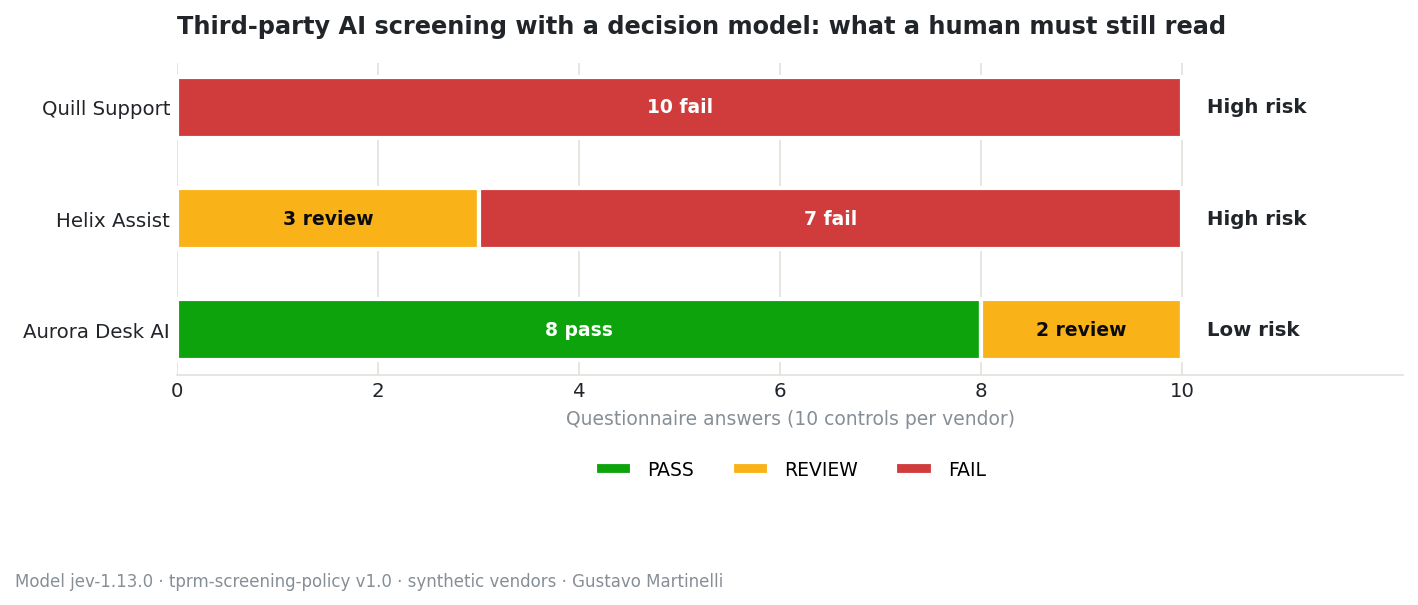

In [24]:
STATUS_COLORS = {"PASS": "#0ca30c", "REVIEW": "#fab219", "FAIL": "#d03b3b"}
LABEL_INK = {"PASS": "white", "REVIEW": "#0b0b0b", "FAIL": "white"}
TEXT, SUBTEXT, HAIRLINE = "#212529", "#868e96", "#e1e0d9"

order = vendor_summary.index.tolist()[::-1]           # highest-risk vendor on top
fig, ax = plt.subplots(figsize=(9.5, 3.6), dpi=150)
left = np.zeros(len(order))
for status in ["PASS", "REVIEW", "FAIL"]:
    values = vendor_summary.loc[order, status].to_numpy()
    bars = ax.barh(order, values, left=left, color=STATUS_COLORS[status], height=0.55,
                   edgecolor="white", linewidth=2, label=status)
    for bar, v in zip(bars, values):
        if v > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + bar.get_height() / 2,
                    f"{v} {status.lower()}", ha="center", va="center",
                    fontsize=9, color=LABEL_INK[status], fontweight="bold")
    left += values

for i, vendor in enumerate(order):
    ax.text(len(CONTROLS) + 0.25, i, f"{vendor_summary.loc[vendor, 'tier']} risk",
            va="center", fontsize=9.5, color=TEXT, fontweight="bold")

ax.set_xlim(0, len(CONTROLS) + 2.2)
ax.set_xticks(range(0, len(CONTROLS) + 1, 2))
ax.set_xlabel("Questionnaire answers (10 controls per vendor)", color=SUBTEXT, fontsize=9)
ax.tick_params(colors=TEXT, labelsize=9.5, length=0)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(HAIRLINE)
ax.grid(axis="x", color=HAIRLINE, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title("Third-party AI screening with a decision model: what a human must still read",
             loc="left", fontsize=11.5, color=TEXT, fontweight="bold", pad=14)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False, fontsize=9)
fig.text(0.01, -0.10, f"Model {MODEL} · {POLICY_VERSION} · synthetic vendors · {AUTHOR}",
         fontsize=8, color=SUBTEXT)
plt.tight_layout()
CHART_PATH = "vendor_screening.png"
fig.savefig(CHART_PATH, bbox_inches="tight", facecolor="white")
plt.show()

## 7. 📋 Assessment Report

### 7.1 A screening report a non-technical reviewer can read

Probabilities and thresholds mean little to a procurement lead or a DPO. Here we translate everything above into a **plain-language screening report**, saved as `tprm_screening_report.txt`. It contains:

- **Identification**: model version, policy version, date, number of answers
- **Vendor tiers** and the reason for each
- **Findings** (FAIL) and the **human review queue** (REVIEW), with the model's reasons
- **Method and limitations**: what the screening did and, more importantly, what it did *not* do

> 🏛️ **Governance note:** A report that says "screening" in the title and lists its limitations is more useful, and more defensible, than one that says "assessment" and hides them. ISO/IEC 42001 A.8.2 asks for documentation that lets interested parties understand the system; this includes understanding its limits.

In [25]:
now = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

def findings_block(status: str) -> list[str]:
    sub = decisions[decisions["status"] == status].sort_values(["vendor", "control_id"])
    if sub.empty:
        return ["   none"]
    return [f"   - {r.vendor} / {r.control_id} {r.control}: {r.reasons}" for r in sub.itertuples()]

lines = [
    "THIRD-PARTY AI RISK SCREENING - REPORT",
    "=" * 60,
    f"Generated:         {now}",
    f"Decision model:    {', '.join(decisions['model'].unique())} (TypeSafe AI, pinned)",
    f"Decision policy:   {POLICY_VERSION}",
    f"Scope:             {len(decisions)} answers · {decisions['vendor'].nunique()} vendors · {len(CONTROLS)} controls",
    f"Critical controls: {', '.join(sorted(CRITICAL_CONTROLS))}",
    f"Overall:           {summary['PASS']} PASS · {summary['REVIEW']} REVIEW · {summary['FAIL']} FAIL",
    "",
    "1. VENDOR TIERS",
    *[f"   {v}: {vendor_summary.loc[v, 'tier']} risk "
      f"({vendor_summary.loc[v, 'FAIL']} fail, {vendor_summary.loc[v, 'REVIEW']} review, {vendor_summary.loc[v, 'PASS']} pass"
      f"{'; critical: ' + vendor_summary.loc[v, 'critical_fails'] if vendor_summary.loc[v, 'critical_fails'] != '—' else ''})"
      for v in vendor_summary.index],
    "",
    "2. FINDINGS TO CONFIRM (FAIL)",
    *findings_block("FAIL"),
    "",
    "3. HUMAN REVIEW QUEUE (REVIEW)",
    *findings_block("REVIEW"),
    "",
    "4. PASSED BY SCREENING (PASS) - spot-check by sampling",
    *findings_block("PASS"),
    "",
    "5. METHOD AND LIMITATIONS",
    "   - Each answer was judged by a decision model on four typed questions",
    "     (addresses the control, type of evidence, specificity, red flag).",
    "   - Statuses were assigned by an explicit, versioned policy in code,",
    "     not by the model. Thresholds are listed in the notebook, Section 5.",
    "   - This is a SCREENING, not an assessment: it ranks attention, it does",
    "     not establish compliance. Evidence (reports, certificates, contracts)",
    "     was not reviewed.",
    "   - The model may be wrong; probabilities are estimates, not facts.",
    "   - Vendors and answers are synthetic, created for educational purposes.",
    "   - A human must confirm every finding before it is communicated.",
]
report = "\n".join(lines)
print(report)

with open("tprm_screening_report.txt", "w", encoding="utf-8") as f:
    f.write(report)
decisions.drop(columns=["raw"]).to_csv("tprm_decision_log.csv", index=False)
with open("tprm_decision_log_raw.json", "w", encoding="utf-8") as f:
    json.dump([r["raw"] for r in log], f, indent=1)

THIRD-PARTY AI RISK SCREENING - REPORT
Generated:         2026-11-01 16:13 UTC
Decision model:    jev-1.13.0 (TypeSafe AI, pinned)
Decision policy:   tprm-screening-policy v1.0
Scope:             30 answers · 3 vendors · 10 controls
Critical controls: C01, C05, C07
Overall:           8 PASS · 5 REVIEW · 17 FAIL

1. VENDOR TIERS
   Quill Support: High risk (10 fail, 0 review, 0 pass; critical: C01, C05, C07)
   Helix Assist: High risk (7 fail, 3 review, 0 pass; critical: C01, C05, C07)
   Aurora Desk AI: Low risk (0 fail, 2 review, 8 pass)

2. FINDINGS TO CONFIRM (FAIL)
   - Helix Assist / C01 Use of customer data for training: red flag (p=0.97)
   - Helix Assist / C04 Access control and logging: red flag (p=0.88)
   - Helix Assist / C05 Security incident notification: red flag (p=0.83); does not address the control (p=0.14)
   - Helix Assist / C06 AI incident and malfunction reporting: red flag (p=0.84)
   - Helix Assist / C07 Human oversight and escalation: red flag (p=0.92)
   - Heli

### 7.2 Professional PDF report

This cell turns the screening report into a **formatted PDF**: a header, identification data, the vendor tiers, the chart, the findings and review queue, and the method and limitations.

It installs one small library (`fpdf2`) and uses the DejaVu font that ships with matplotlib, so special characters display correctly.

> 🏛️ **Governance note:** A screening record that is **formatted, dated and tied to a model and a policy version** can be filed with the vendor's contract and reopened at renewal time.

In [26]:
%pip install -q fpdf2

from fpdf import FPDF
from fpdf.enums import XPos, YPos

PDF_PATH = "tprm_screening_report.pdf"
FONT_DIR = os.path.join(matplotlib.get_data_path(), "fonts", "ttf")

NAVY, GRAY, DARK = (22, 50, 79), (134, 142, 150), (33, 37, 41)
STATUS_RGB = {"PASS": (12, 163, 12), "REVIEW": (196, 130, 0), "FAIL": (208, 59, 59)}
TIER_RGB = {"Low": (12, 163, 12), "Medium": (196, 130, 0), "High": (208, 59, 59)}


class ReportPDF(FPDF):
    def footer(self):
        self.set_y(-12)
        self.set_font("DejaVu", "", 7.5)
        self.set_text_color(*GRAY)
        self.cell(0, 5, f"{AUTHOR} · Educational material with synthetic data, not legal advice")
        self.set_x(self.l_margin)
        self.cell(0, 5, f"Page {self.page_no()}/{{nb}}", align="R")


pdf = ReportPDF(format="A4")
pdf.add_font("DejaVu", "", os.path.join(FONT_DIR, "DejaVuSans.ttf"))
pdf.add_font("DejaVu", "B", os.path.join(FONT_DIR, "DejaVuSans-Bold.ttf"))
pdf.set_auto_page_break(True, margin=18)
pdf.add_page()
W = pdf.epw


def section(title):
    pdf.ln(4)
    pdf.set_font("DejaVu", "B", 11.5)
    pdf.set_text_color(*NAVY)
    pdf.cell(0, 7, title, new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_draw_color(222, 226, 230)
    pdf.set_line_width(0.3)
    pdf.line(pdf.l_margin, pdf.get_y(), pdf.l_margin + W, pdf.get_y())
    pdf.ln(2)


def row(label, value, bold=False, color=DARK):
    pdf.set_font("DejaVu", "", 9.5)
    pdf.set_text_color(*GRAY)
    pdf.cell(45, 6, label)
    pdf.set_font("DejaVu", "B" if bold else "", 9.5)
    pdf.set_text_color(*color)
    pdf.multi_cell(W - 45, 6, value, new_x=XPos.LMARGIN, new_y=YPos.NEXT)


def finding(r):
    color = STATUS_RGB[r.status]
    pdf.set_font("DejaVu", "B", 9)
    pdf.set_text_color(*color)
    pdf.cell(18, 5.5, r.status)
    pdf.set_text_color(*DARK)
    pdf.cell(0, 5.5, f"{r.vendor} · {r.control_id} {r.control}", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.set_font("DejaVu", "", 8.5)
    pdf.set_text_color(*GRAY)
    pdf.set_x(pdf.l_margin + 18)
    pdf.multi_cell(W - 18, 4.8, r.reasons, new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.ln(1)


# ---- Header band ----
pdf.set_fill_color(*NAVY)
pdf.rect(0, 0, 210, 30, style="F")
pdf.set_fill_color(12, 163, 12)
pdf.rect(0, 30, 210, 1.5, style="F")
pdf.set_xy(pdf.l_margin, 8)
pdf.set_font("DejaVu", "B", 15)
pdf.set_text_color(255, 255, 255)
pdf.cell(0, 8, "Third-Party AI Risk Screening Report", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_font("DejaVu", "", 9)
pdf.cell(0, 6, "Decision-model screening of vendor questionnaire answers · synthetic vendors", new_x=XPos.LMARGIN, new_y=YPos.NEXT)
pdf.set_y(38)

section("1. Identification")
row("Generated", now)
row("Decision model", f"{', '.join(decisions['model'].unique())} (TypeSafe AI, pinned version)")
row("Decision policy", POLICY_VERSION)
row("Scope", f"{len(decisions)} answers · {decisions['vendor'].nunique()} vendors · {len(CONTROLS)} controls")
row("Critical controls", ", ".join(f"{c} {CONTROL_NAME[c]}" for c in sorted(CRITICAL_CONTROLS)))
row("Overall", f"{summary['PASS']} PASS · {summary['REVIEW']} REVIEW · {summary['FAIL']} FAIL", bold=True)

section("2. Vendor tiers")
for v in vendor_summary.index:
    t = vendor_summary.loc[v, "tier"]
    crit = vendor_summary.loc[v, "critical_fails"]
    row(v, f"{t} risk  ·  {vendor_summary.loc[v, 'FAIL']} fail / {vendor_summary.loc[v, 'REVIEW']} review / "
           f"{vendor_summary.loc[v, 'PASS']} pass" + (f"  ·  critical: {crit}" if crit != "—" else ""),
        bold=True, color=TIER_RGB[t])
pdf.ln(2)
pdf.image(CHART_PATH, x=pdf.l_margin, w=W)

pdf.add_page()
section("3. Findings to confirm (FAIL)")
for r in decisions[decisions["status"] == "FAIL"].sort_values(["vendor", "control_id"]).itertuples():
    finding(r)
section("4. Human review queue (REVIEW)")
for r in decisions[decisions["status"] == "REVIEW"].sort_values(["vendor", "control_id"]).itertuples():
    finding(r)
section("5. Passed by screening (PASS) - spot-check by sampling")
pdf.set_font("DejaVu", "", 8.5)
pdf.set_text_color(*DARK)
passed = decisions[decisions["status"] == "PASS"].sort_values(["vendor", "control_id"])
for v, g in passed.groupby("vendor"):
    pdf.multi_cell(W, 5, f"{v}: {', '.join(g['control_id'])}", new_x=XPos.LMARGIN, new_y=YPos.NEXT)

section("6. Method and limitations")
pdf.set_font("DejaVu", "", 9)
pdf.set_text_color(*DARK)
for text in [
    "Each answer was judged by a decision model on four typed questions: whether it addresses the control, "
    "the type of evidence offered, its specificity, and whether it reveals a red flag.",
    "Statuses were assigned by an explicit, versioned policy in code, not by the model. The thresholds are "
    f"documented in the accompanying notebook ({POLICY_VERSION}).",
    "This is a screening, not an assessment. It ranks where human attention should go first; it does not "
    "establish compliance. No evidence (reports, certificates, contracts) was reviewed.",
    "The model may be wrong. Probabilities are estimates, not facts. Every finding must be confirmed by a "
    "human before it is communicated to a vendor or used in a decision.",
    "Vendors and answers are synthetic and were created for educational purposes.",
]:
    pdf.multi_cell(W, 5, "•  " + text, new_x=XPos.LMARGIN, new_y=YPos.NEXT)
    pdf.ln(0.5)

pdf.output(PDF_PATH)
print(f"PDF saved to {PDF_PATH} ({os.path.getsize(PDF_PATH) / 1024:.0f} KB)")

PDF saved to tprm_screening_report.pdf (77 KB)


### 7.3 Downloading the results

This cell downloads the five outputs to your computer:

- `vendor_screening.png`: the chart, a candidate cover for the post
- `tprm_screening_report.pdf`: the formatted report
- `tprm_screening_report.txt`: the plain-text report
- `tprm_decision_log.csv`: one row per answer, with every probability, status and reason
- `tprm_decision_log_raw.json`: the full typed responses from Jev, for the audit trail

*If your browser blocks multiple downloads, allow them for colab.research.google.com, or use the 📁 Files panel on the left.*

In [27]:
OUTPUTS = [CHART_PATH, PDF_PATH, "tprm_screening_report.txt", "tprm_decision_log.csv", "tprm_decision_log_raw.json"]

try:
    from google.colab import files
    for path in OUTPUTS:
        files.download(path)
except ImportError:
    print("Not running in Colab. The files are saved in the current folder:")
    for path in OUTPUTS:
        print(f"  - {path}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. 🎯 Key Takeaways

1. **Typed outputs are auditable outputs.** Every judgment in this notebook is a number or a label with a model version, a timestamp and an input hash. That is a decision log, not a chat transcript.
2. **The model judges; the code decides.** The thresholds in Section 5 are the real policy. They are visible, versioned and changeable by a risk owner who cannot read a neural network.
3. **The gray zone is a feature.** Forcing anything between 0.30 and 0.70 into human review is how oversight becomes a mechanism instead of a promise.
4. **Vague answers are a signal.** Marketing language that could be pasted under any control is exactly what a screening layer should surface, because it is exactly what a tired human skips.
5. **The screening tool is a third party too.** Pinned version, synthetic data, no real vendor documents, measured (not quoted) performance. Governance applies to the tools we use to govern.

## 9. ⚠️ Limitations

- **Screening ≠ assessment.** Nothing here reviewed a SOC 2 report, a contract or a technical configuration. The output is a prioritized reading list for a human assessor.
- **The model can be wrong, and confidently so.** TypeSafe documents known failure modes ("jaggedness") for each Jev version. Calibration should be checked on *your* data before trusting any threshold.
- **Question wording matters.** The `red_flag` instruction lists examples; a practice not covered by the wording may be missed. Treat the questions as a versioned artifact, like the policy.
- **Early access.** At the time of writing Jev is in early access and pricing, limits and versions may change. Pin the version, log what the API reports, and re-validate after upgrades.
- **Synthetic vendors.** The three vendors were written to illustrate patterns. Real questionnaires are longer, messier and sometimes contradictory across answers; cross-answer consistency is not checked here.
- **Confidentiality.** Real vendor material often cannot be sent to another third-party API. Check contracts and data-processing agreements first, or use a deployment that meets them.
- **Technical screening ≠ legal compliance.** Regulations also require contracts, due diligence records, risk assessments and ongoing monitoring of suppliers.

> *This notebook is for educational purposes and does not constitute legal advice.*

## 10. 🚀 Going Further

### 10.1 Experiments to try in this notebook
- Change `REVIEW_BAND` to `(0.20, 0.80)` and watch how much more work lands on humans. Where is *your* comfort line?
- Add a fifth question, for example a Noul for "the answer contradicts another answer from the same vendor", and feed two answers in the `state`.
- Replace the synthetic answers with your own **anonymized, non-confidential** examples and compare Jev's judgments with yours. Where they disagree is where the interesting conversation starts.
- Run the same 30 answers again next month with `jev-latest` and diff the decision logs. That diff *is* a model change report.

### 10.2 Tools and references for real-world third-party AI risk
- **[TypeSafe docs](https://docs.typesafe.ai/)**: Jev primitives (Noul, Choice, Score), SDKs, versioning and documented failure modes.
- **Shared Assessments SIG** and **CAIQ (Cloud Security Alliance)**: standardized vendor questionnaires you can map controls to.
- **Model Cards** and **Datasheets for Datasets**: what to ask vendors for under control C08.

### 10.3 Governance frameworks
- **ISO/IEC 42001**: AI management systems; Annex A.10 covers third-party and customer relationships
- **ISO/IEC 23894**: AI risk management
- **ISO/IEC 27001 / 27002**: Annex A 5.19–5.23, supplier relationships and cloud services
- **NIST AI RMF**: GOVERN 6 (third-party risk) and MAP 4 (risks from third-party components)
- **EU AI Act**: Art. 13 (transparency to deployers), Art. 14 (human oversight), Art. 26 (deployer obligations)

## 📚 References

| Reference | Topic |
|---|---|
| [TypeSafe AI documentation](https://docs.typesafe.ai/) | Jev, System One models, Noul / Choice / Score primitives, Python SDK |
| [TypeSafe quick start](https://docs.typesafe.ai/introduction/quickstart) | First call to Jev in Python |
| [ISO/IEC 42001:2023](https://www.iso.org/standard/81230.html) | AI management system; Annex A controls cited in this notebook |
| [ISO/IEC 27001:2022](https://www.iso.org/standard/27001) | Information security management; Annex A controls cited in this notebook |
| [ISO/IEC 23894:2023](https://www.iso.org/standard/77304.html) | AI risk management |
| [NIST AI Risk Management Framework](https://www.nist.gov/itl/ai-risk-management-framework) | GOVERN 6 and MAP 4: third-party risk |
| [EU AI Act, Regulation (EU) 2024/1689](https://eur-lex.europa.eu/eli/reg/2024/1689/oj) | Arts. 12, 13, 14, 26 and 73 |
| [GDPR, Regulation (EU) 2016/679](https://eur-lex.europa.eu/eli/reg/2016/679/oj) | Arts. 5, 28 and 33 |
| [LGPD, Lei nº 13.709/2018](https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm) | Arts. 15, 16, 39 and 48 |
| [Kahneman, *Thinking, Fast and Slow* (2011)](https://en.wikipedia.org/wiki/Thinking,_Fast_and_Slow) | Origin of the "System One" metaphor |

## 🤝 Let's Connect

Thank you for exploring this notebook! 🙏

If it was useful, I'd love to hear your thoughts. **Where would you set the threshold for "this answer needs a human"?**

⭐ **Enjoyed it?** [Star the repository](https://github.com/gustavomartinellidev/ai-governance-lab) and follow me for the next notebooks.

<a href="https://www.linkedin.com/in/gustavomartinelli/" target="_blank">🔗 <b>Gustavo Martinelli</b> on LinkedIn</a>

*Feel free to copy, adapt and share this notebook, with attribution.*